In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import skeliner as sk

from pywarper import layers, warpers

`pywarper==0.3.0` added a dedicated `layers` API for creating global conformal mapping for EyeWire II. Previously this is done separately in standalone analysis notebooks and the mapping was cached and shared for `flatone`. The previous versions of the mappings cached in `flatone` have different extent of defects for cells at the edges where the OFF SACs where cut-off at the upper z bound (for which the surface extrapolation might not be reasonable), and the `layers` module is built specifically to address this issue.

Assuming you have your data stored in the either `folder/<segID>.npz` or `folder/<segID>/skeleton.npz`, you can load all cells with  `layers.load_cells`:

In [2]:
SACS = Path("../../skeliner/dev/SACs")
A17 = Path("../../skeliner/dev/data/mutilayers/AC/A17_large")

on  = layers.load_cells(SACS / "sac-on", "{id}/skeleton.npz")
off = layers.load_cells(SACS / "sac-off","{id}/skeleton.npz",)

print(len(on), len(off))

1037 686


Then the SAC bands can be fitted with one call. And on top of that, you can add more layers other than the two SAC bands to anchor the cells upper or lower than the bands. Two types of extra layers can be added: soma layer, or arbor layers. 

Soma layer (`layers.soma_layer()`) is computed from the soma only, while the arbor layer (`layers.stratum_layer`) is computed the same way we extract the SAC bands.

So far I found adding the ON SAC soma alone should be enough to correct most out of SAC bands drift, while adding more layers (such as A17) is only marginally better.

In [3]:
bands = layers.fit_bands(on, off)
on_soma = layers.soma_layer("on_soma", on, bands)
print(layers.report(bands, [on_soma]))

tissue 51.8% of the map; columns with both bands 30,809, ON only 4,697, OFF only 118
band gap 14.7 um (5-95% 12.8-16.8), 11.3-19.1 over the whole map
on: depth +0.00, 1,037 cells, observed over 99.8% of the tissue; 1,418 columns cut off at a z bound, 683 too thin
off: depth +12.00, 686 cells, observed over 86.9% of the tissue; 1,039 columns cut off at a z bound, 862 too thin
on_soma: depth -14.92, 1,037 cells, observed over 95.2% of the tissue; 971 somata used, 62 without room, 2 off the level; field -17.7 to -12.9 in the tissue


In [4]:
new_mapping = layers.build_map(bands, [on_soma], conformal_jump=1)

In [5]:
# layers.save_map(mapping, path="./global_map_j1_20261125.npz")
# new_mapping = layers.load_map(path="./global_map_j1_20261125.npz")

In [6]:
def load_old_global_map(path) -> dict:
    with np.load(path, allow_pickle=True) as z:
        return {k: v for k, v in z.items()}

old_mapping = load_old_global_map("../dev/SACs/surfaces/global_map_j1_20260807.npz")

In [7]:
maps = {"pywarper v0.3": new_mapping, "pywarper v0.2": old_mapping}

Text(0.5, 0, 'x (µm)')

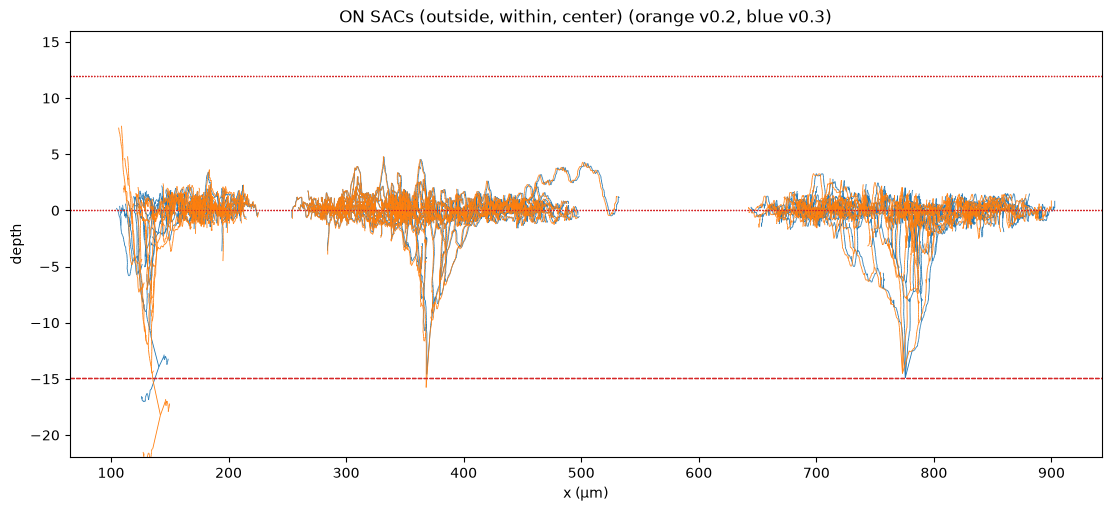

In [8]:
# cell = "720575940557511018"
# skel = sk.io.load_skeleton(A17 / cell / "skeleton.npz")
# skel.convert_unit("um")

cells = {"center": "720575940561010110", "middle": "720575940545899781", "edge": "720575940568678897"}
skels = {k: sk.io.load_skeleton(SACS / "sac-on" / v / "skeleton.npz") for (k,v) in cells.items()}

fig, ax = plt.subplots(1, 1, figsize=(11, 5), sharex=True, constrained_layout=True)
color = {"pywarper v0.3": "C0", "pywarper v0.2": "C1"}
for (name, mapping) in maps.items():
    for (pos, skel) in skels.items():
        skel.convert_unit("um")
        nodes = np.asarray(warpers.warp_skeleton(skel, mapping).nodes)
        ax.add_collection(LineCollection(nodes[skel.edges][:, :, [1, 2]], colors=color[name], linewidths=0.6))
        for depth, style in ((0, ":"), (12, ":"), (on_soma.depth, "--")):
            ax.axhline(depth, color="C3", ls=style, lw=0.8)
        ax.autoscale()
        ax.set_ylim(-22, 16)
        ax.set_title(f"ON SACs (outside, within, center) (orange v0.2, blue v0.3)")
        ax.set_ylabel("depth")
    
ax.set_xlabel("x (µm)")

Text(0.5, 0, 'x (µm)')

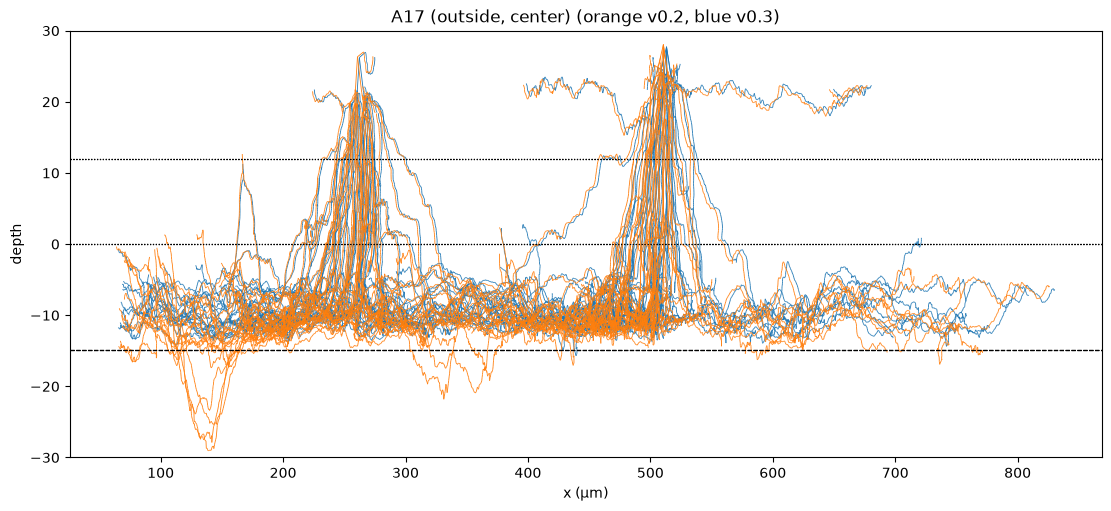

In [9]:
a17s = {"center": "720575940569221895", "edge": "720575940557511018"}
skels = {k: sk.io.load_skeleton(A17 / cell / "skeleton.npz") for (k, cell) in a17s.items()}

fig, ax = plt.subplots(1, 1, figsize=(11, 5), sharex=True, constrained_layout=True)
color = {"pywarper v0.3": "C0", "pywarper v0.2": "C1"}
for (name, mapping) in maps.items():
    for (pos, skel) in skels.items():
        skel.convert_unit("um")
        nodes = np.asarray(warpers.warp_skeleton(skel, mapping).nodes)
        ax.add_collection(LineCollection(nodes[skel.edges][:, :, [0, 2]], colors=color[name], linewidths=0.6))
        for depth, style in ((0, ":"), (12, ":"), (on_soma.depth, "--")):
            ax.axhline(depth, color="k", ls=style, lw=0.8)
        ax.autoscale()
        ax.set_ylim(-30, 30)
        ax.set_title(f"A17 (outside, center) (orange v0.2, blue v0.3)")
        ax.set_ylabel("depth")
    
ax.set_xlabel("x (µm)")

In [10]:
%load_ext watermark
%watermark --time --date --timezone --updated --python --iversions --watermark

Last updated: 2026-11-25 14:36:29 CET

Python implementation: CPython
Python version       : 3.13.11
IPython version      : 9.18.1

matplotlib: 3.11.2
numpy     : 2.5.5
pywarper  : 0.3.0
skeliner  : 0.4.1

Watermark: 2.6.0

